# 10 · Language requirements

How often do IT job postings mention Japanese, English, Korean or Chinese, and for which jobs?

**Method.** A language flag fires when the title or description *mentions* the language or its certificate (Japanese: Japanese, tiếng Nhật, JLPT, kana characters, "Bridge SE", BSE, comtor; English: English, tiếng Anh, IELTS, TOEIC, TOEFL; Korean: Korean, tiếng Hàn, TOPIK, hangul; Chinese: Chinese, tiếng Trung, Mandarin, HSK). A mention is usually, not always, a requirement. Longer descriptions mention more, so each trend is drawn for all sources and inside the two control sources whose descriptions keep the same length (LinkedIn, Monster Asia). Shares are of postings that have a description.

In [1]:
import pandas as pd
from IPython.display import display

from vnjobs.analysis import core as a
from vnjobs.analysis import languages as l

a.apply_style()
con = a.connect()
df = a.load_features(con)

## 1. Over time

Share of postings with a description that mention each language.

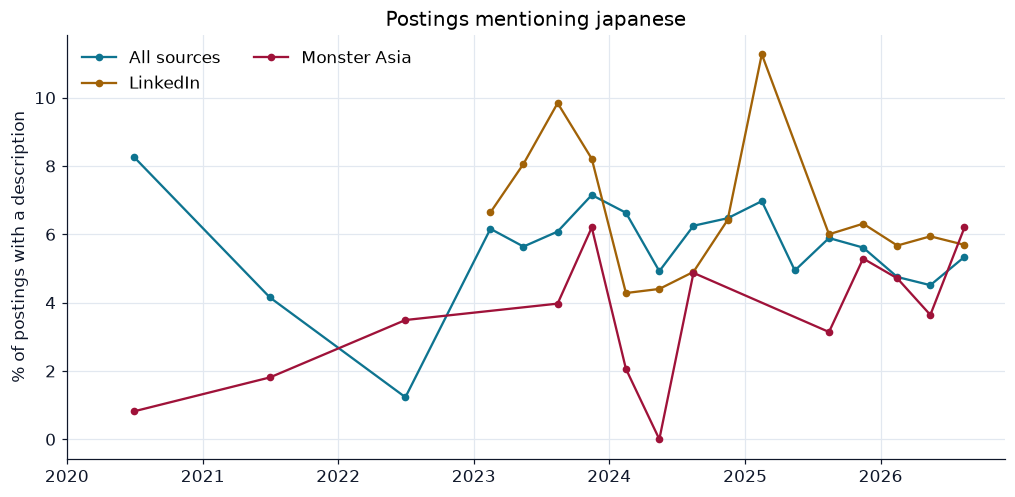

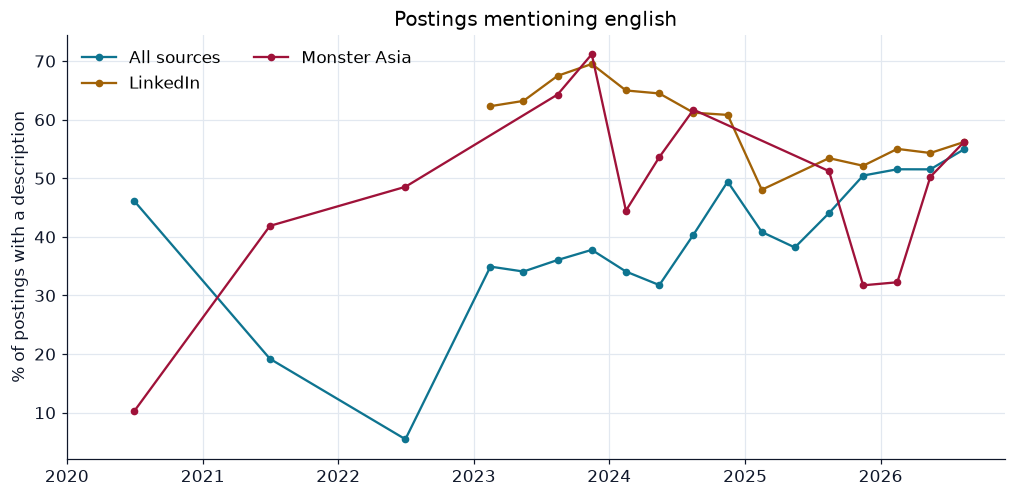

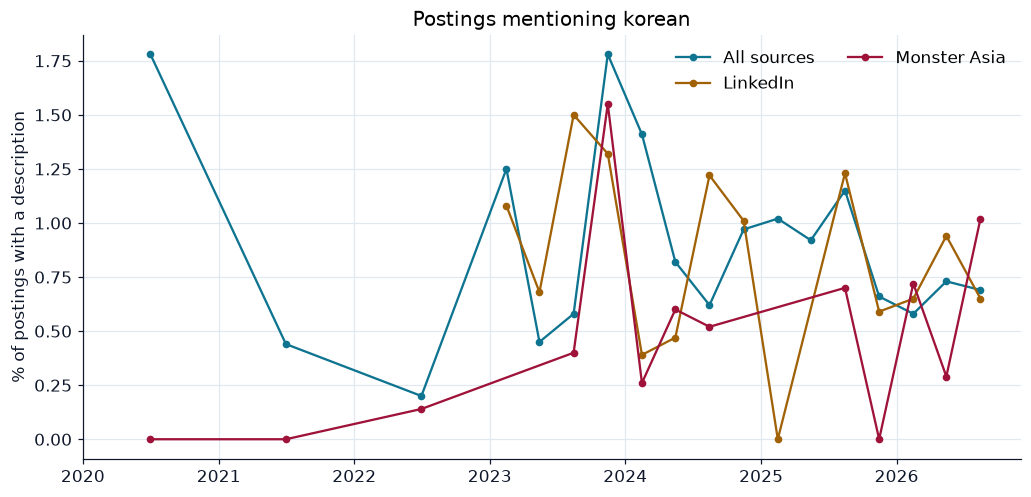

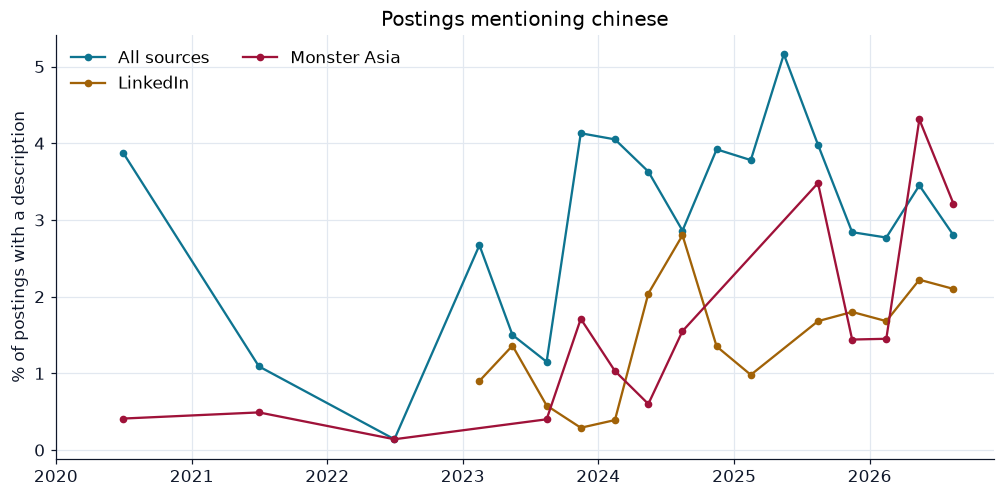

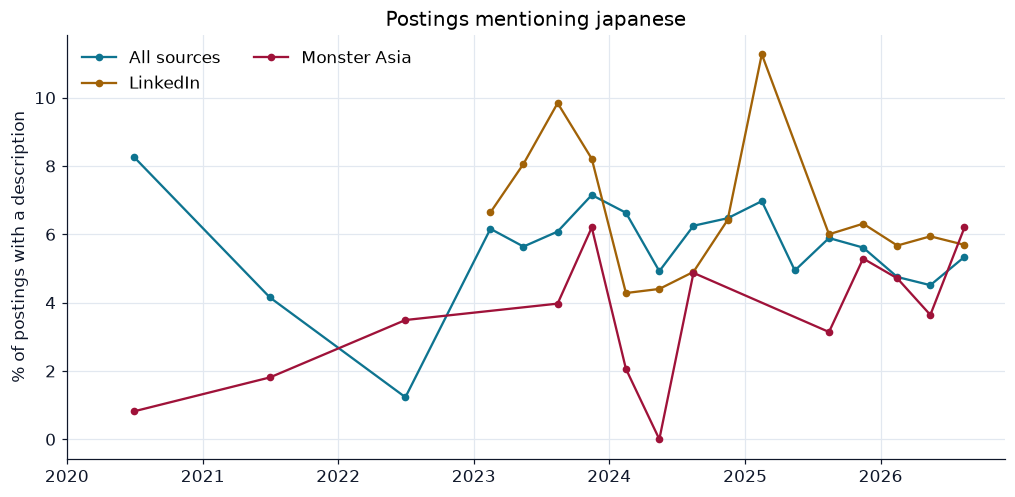

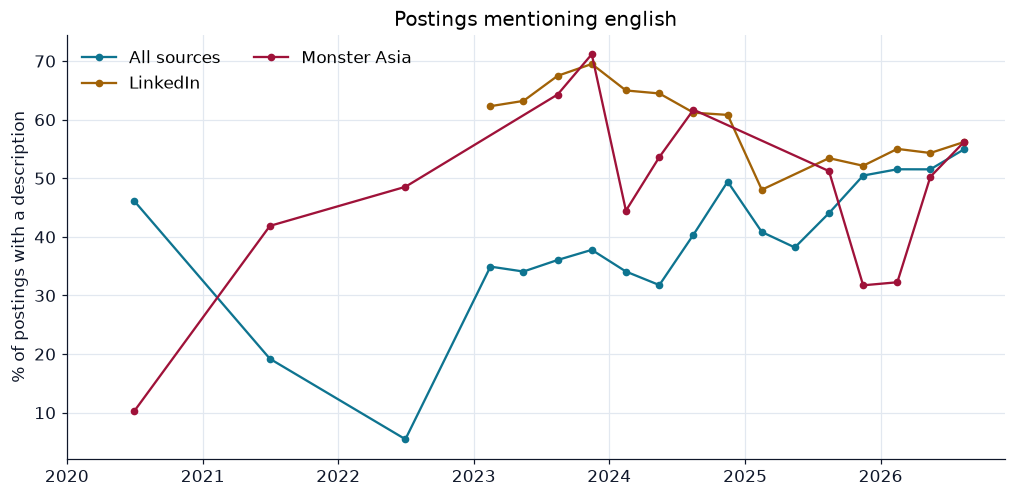

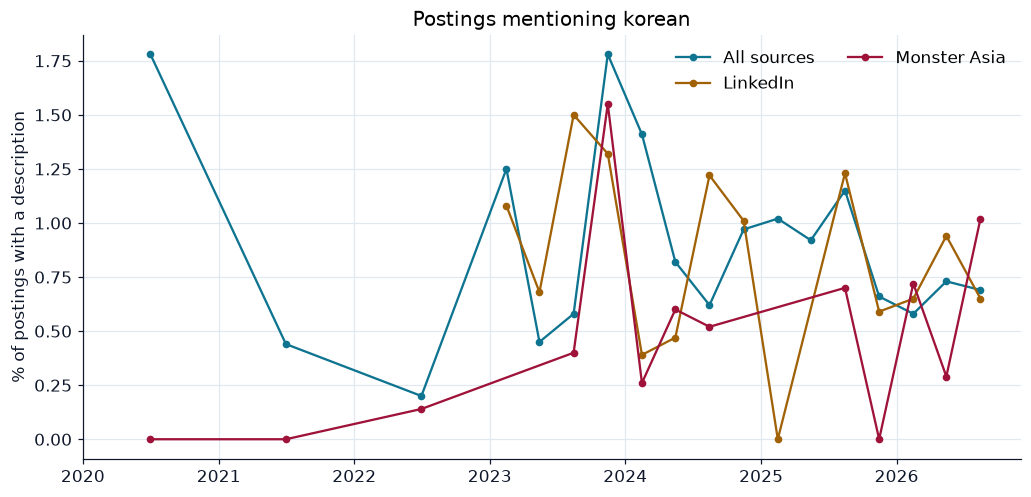

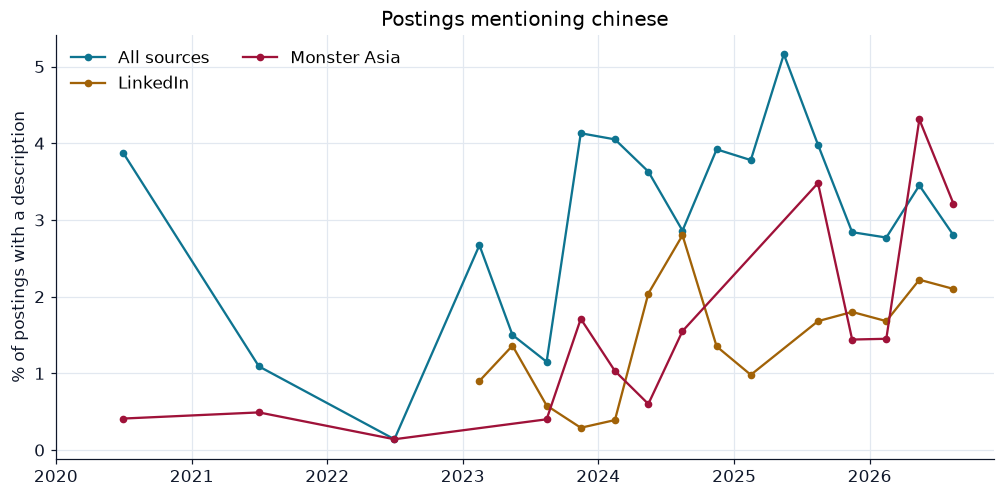

In [2]:
for language in l.LANGUAGES:
    series = l.mention_series(df, language)
    fig = a.trend_lines(
        series, f"Postings mentioning {language}", "% of postings with a description"
    )
    a.save_chart(fig, f"10-{language}-mentions")
    rows = [f.assign(scope=n) for n, f in series.items()]
    a.save_table(pd.concat(rows).drop(columns="period_date"), f"10-{language}-mentions")
    display(fig)

## 2. By role

Share of postings mentioning each language, per role, January 2025 onward.

In [3]:
by_role = l.by_role(df)
a.save_table(by_role, "10-languages-by-role")
by_role

,role,postings,japanese,english,korean,chinese
0,qa_test,9165,6.8,57.1,0.9,4.7
1,technical_non_software,8503,3.4,38.3,0.8,7.4
2,software_other,8452,7.4,50.4,0.9,4.2
3,data,6449,2.3,41.6,0.2,1.2
4,it_support_infra,6352,4.4,50.8,0.7,4.6
5,backend,6159,8.6,53.2,1.7,0.9
6,ai_ml,6060,4.1,42.7,0.4,1.4
7,devops_cloud,4830,4.6,52.4,0.5,1.7
8,fullstack,3314,4.8,56.4,0.4,0.4
9,other,2637,4.6,50.4,0.9,6.5


## 3. By level

The same, per seniority level (postings with a known level, 2025 on).

In [4]:
by_level = l.by_level(df)
a.save_table(by_level, "10-languages-by-level")
by_level

,level,postings,japanese,english,korean,chinese
0,intern,3176,6.4,49.4,0.7,1.6
1,junior,14436,5.7,50.6,0.7,3.0
2,lead,5519,3.9,52.2,0.3,1.7
3,manager,1171,5.3,47.9,1.7,3.3
4,mid,11039,5.0,52.3,0.8,3.6
5,mid_senior,4320,6.5,54.6,1.1,1.5
6,senior,13417,4.4,54.0,0.7,2.0


## 4. Who asks for Japanese

Employers with the most Japanese-mentioning postings from 2025 on, and the commonest titles among all Japanese-mentioning postings (a sanity check of the flag).

In [5]:
employers = l.japanese_employers(df)
a.save_table(employers, "10-japanese-employers")
employers

,company,japanese_postings,share_of_their_postings
0,Dxc Technology,334,66.4
1,Bosch,258,21.3
2,Reeracoen,180,57.5
3,Vti,168,91.8
4,Hitachi Digital Services,92,24.1
5,Tinhvan Software,89,93.7
6,Sun,84,81.6
7,Rgf Hr Agent,82,90.1
8,FPT,80,5.3
9,Kaopiz,77,71.3


In [6]:
titles = l.japanese_titles(df)
a.save_table(titles, "10-japanese-titles")
titles

,title,postings
0,java developer,43
1,devops engineer,42
2,nhân viên kỹ thuật,40
3,nhân viên qa,34
4,ai engineer,31
5,python developer,31
6,php developer,30
7,nhân viên it,28
8,bridge software engineer,26
9,bridge system engineer,26


## Findings

1. **Japanese is a steady niche, not a growth story.** 4–7 % of postings that have a description mention Japanese: all sources 4.2 % (2021), 6.2 % (2023-Q1), 7.0 % (2025-Q1), 5.3 % (2026-Q3); LinkedIn about 5.7 % since 2025-Q3.
2. **English is mentioned in about half, and that is not rising.** All sources go from 19 % (2021) to 55 % (2026-Q3), but that is the source mix and longer descriptions: inside LinkedIn it is flat at 62 % (2023-Q1), 53 % (2025-Q3), 56 % (2026-Q3). It is highest for BA/PM (68 %), ERP (59.5 %), embedded (58 %), QA (57 %) and full-stack (56 %), lowest for game (32 %), and about the same at every level (49 % for interns, 54 % for seniors), so English is not asked for more as jobs get senior.
3. **Korean and Chinese are small.** Korean is 0.4–1.3 % of postings; Chinese 1–4 % across all sources and about 2 % on LinkedIn (1.7 % in 2025-Q3, 2.1 % in 2026-Q3).
4. **Japanese is concentrated in a few roles.** ERP and consulting 12.1 %, backend 8.6 %, embedded 8.1 %, frontend 7.7 %, general software 7.4 %; lowest for security (1.7 %), data (2.3 %) and game (3.7 %). Interns (6.4 %) and juniors (5.7 %) mention it slightly more than seniors (4.4 %).
5. **Who asks.** Japan-facing outsourcers and recruiters lead: DXC Technology (334 postings, 66 % of its own), Bosch (258, 21 %), Reeracoen (180, 58 %), VTI (168, 92 %), Hitachi Digital Services (92, 24 %), Tinhvan Software (89, 94 %), Sun* (84, 82 %), RGF HR Agent (82, 90 %), Kaopiz (77, 71 %), Kokoro (71, 66 %). The commonest Japanese-flagged titles include Java, DevOps, QA and AI engineers plus "Bridge Software Engineer" and "Bridge System Engineer", so the flag is picking up what it should.

**What this notebook cannot say:** whether a mention is a requirement or a "nice to have", or the level of language asked for (JLPT levels are not read).
